In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

#plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-ticks')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])

from trips.utilities.weights import smoothed_holder_weights


from msolver import IASGKS, MMGKS, VanillaGKS
from fsolver import IASFGK, MMFGK # VanillaFK

# Setup toy problem

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)

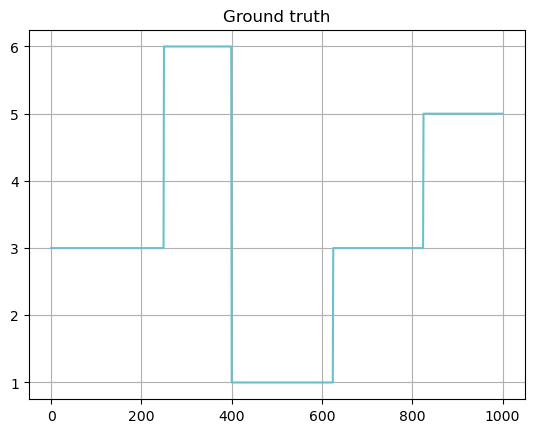

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

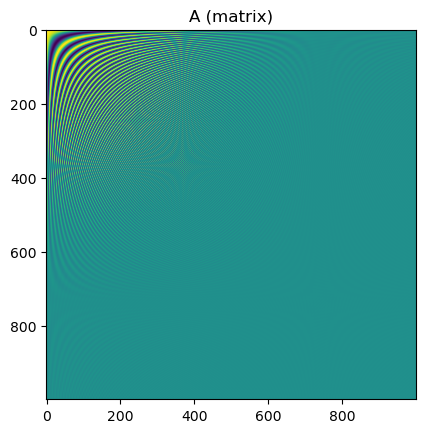

In [6]:
plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [7]:
# # Random undersampling
# np.random.seed(0)
# mask = np.random.binomial(1, 0.8, size=n)
# P = jlinops.Subsampling1DOperator(mask)

# Only first 100 components
mask = np.ones(n)
mask[850:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

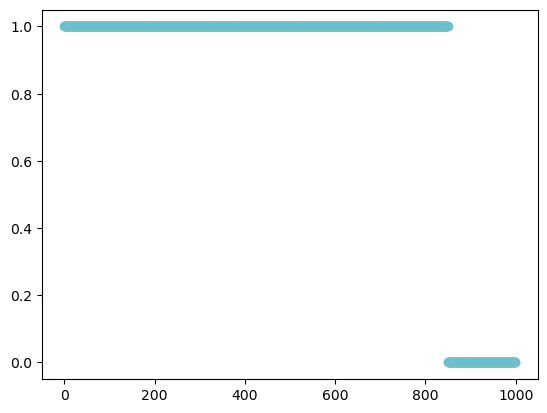

In [8]:
plt.scatter(grid, mask)
plt.show()

In [9]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

In [10]:
noise_var

0.014874805024967963

In [11]:
# # Inverse DCT reconstruction
# plt.plot(A.T @ b)
# plt.plot(ground_truth, color="k")
# plt.show()

In [12]:
# # # Other way of generating the data

# # Generate synthetic data
# np.random.seed(0)
# A = P @ F
# b_true = A @ ground_truth
# noise_sigma = 0.2
# b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])
# noise_var = noise_sigma**2

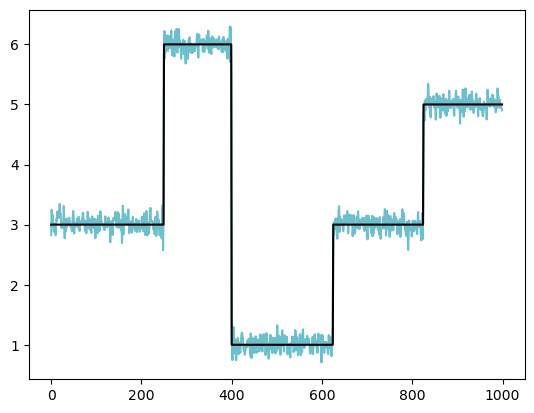

In [13]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [14]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
Kmat = Kmat/np.linalg.norm(Kmat)

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator


# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)
K

#err_norm_sq = len(b) # in expectation

# Build solvers

q = 1.0
epsilon = 1e-4
mmgks_weight_params = {
    "q": q,
    "epsilon": epsilon,
}

gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmfk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b)

# Run all methods

In [15]:
n_its = 200
method = "dp"

ksparsity = 15

vpdata = gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params={}, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished L2 GKS (priorconditioned)")

vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)
print("Finished L2 GKS (vanilla)")

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished S-GKS (priorconditioned)")


recpdata = mmgks_solver.solve_with_priorconditioning(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01}, dim_min=5, dim_max=15)
print("Finished S-GKS (priorconditioned, recycling)")


respdata = mmgks_solver.solve_with_priorconditioning(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01}, restart_dim=15)
print("Finished S-GKS (priorconditioned, restarted)")


data = mmgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
print("Finished S-GKS (vanilla)")

resdata = mmgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=4, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=30)
print("Finished S-GKS (restarted)")


recdata = mmgks_solver.solve(n_iter=800, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=15, max_dim=30, xker=xker, restart_dim=None)
print("Finished S-GKS (recycling)")


mmfkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FK Solver")

rmmfkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mmgks_weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished FK Solver (basis refreshment)")

1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/1d_cosine_easier/../../msolver.py:784: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
17.611311349489167
44.96616401046136
59.73715612227418
69.1230272009651
77.82532481188801
82.23482246811082
85.29059694347556
87.67539774639545
89.5525022854318
90.49584445997532
91.37172106103245
91.97358756912777
92.38486353925255
92.66361686363166
92.87625370277887
93.00251075932182
93.07733589122547
93.11672477487372
93.14577933562217
93.16594906804029
93.1797938804517
93.1888094314861
93.19422106092004
93.19786802061778
93.20078514077991
93.20214373921095
93.20305438847326
93.2036375686653
93.2039931179896
93.20417252222097
93.20428522146378
93.20435960538936
93.20439588497298
93.20441535845984
93.20442496767791
93.20443026300208
93.20443370844501
93.20443530068178
93.20443626553947
93.20443679563839
93.20443704544765
93.20443716423858
93.20443723072721
93.20443726101847
93.20443727753944
93.20443728552861
93.20443728926446
93.20443729104899
93.204437

537.2493094632935
285.1269878023372
111.34131543491141
96.66078033602365
94.01874347952433
93.39037864061936
93.23530223095574
93.20586496856787
93.20449269478554
93.20470704474323
93.20494572469659
93.20472652833938
93.20451263604834
93.20445024115533
93.20443234157439
93.2044369860529
93.2044366699034
93.20443670626008
93.20443693593369
93.20443710739094
93.20443721940977
93.20443729346724
93.20443730823656
93.20443729535519
93.20443729336903
93.20443729350706
93.20443729277417
93.20443729256546
93.20443729246486
93.2044372924997
93.20443729253064
93.20443729253533
93.20443729253417
93.20443729253196
93.20443729253451
93.20443729253516
93.204437292535
93.2044372925342
93.2044372925343
93.20443729253357
93.20443729253375
93.20443729253373
93.20443729253513
93.20443729253533
93.20443729253448
93.2044372925355
93.20443729253338
93.20443729253343
93.20443729253464
93.20443729253375
93.20443729253526
93.20443729253614
93.20443729253532
93.20443729253508
93.20443729253417
93.20443729253346

1e-07
1e-07
1e-07
61.10586859786921
97.33036804799852
107.36970337439328
119.11412962633578
129.08524540492266
138.15379185663983
146.2582683851058
153.0817674411983
158.84822331178265
163.57457091298932
167.56015146787038
170.92098414528186
173.78292117849057
176.22896338241492
178.3553803418239
180.20936836132628
181.8388928592476
183.2827003936754
184.5677261066913
185.7181855403382
186.75321316860132
187.68841067634466
188.53675899519402
189.30920854898147
190.0149401960294
190.66170015105584
191.25614300047718
191.80400580883384
192.31019877058284
192.7789969719812
193.2141294175376
193.61884989811506
193.99602444967178
194.34818208416104
194.67754897963542
194.98611654001496
195.27565229951867
195.54773637327978
195.80378763049248
196.04507987861152
196.2727596903197
196.48786617476205
196.69133708661786
196.88402405830914
197.0667027307918
197.2400783361637
197.40479468558075
197.56144163895186
197.71055802016107
197.85263871392212
197.9881385710896
198.11747561475354
198.241035

1e-07
1e-07
1e-07
61.10586859786921
97.33036804799852
107.36970337439328
119.11412962633578
129.08524540492266
138.15379185663983
146.2582683851058
153.0817674411983
158.84822331178265
163.57457091298932
167.56015146787038
170.92098414528186
173.78292117849057
176.22896338241492
178.3553803418239
180.20936836132628
181.8388928592476
183.2827003936754
184.5677261066913
185.7181855403382
186.75321316860132
187.68841067634466
188.53675899519402
189.30920854898147
190.0149401960294
190.66170015105584
191.25614300047718
191.80400580883384
192.31019877058284
192.7789969719812
193.2141294175376
193.61884989811506
193.99602444967178
194.34818208416104
194.67754897963542
194.98611654001496
195.27565229951867
195.54773637327978
195.80378763049248
196.04507987861152
196.2727596903197
196.48786617476205
196.69133708661786
196.88402405830914
197.0667027307918
197.2400783361637
197.40479468558075
197.56144163895186
197.71055802016107
197.85263871392212
197.9881385710896
198.11747561475354
198.241035

1e-07
1e-07
1e-07
61.10586859786921
97.33036804799852
107.36970337439328
119.11412962633578
129.08524540492266
138.15379185663983
146.2582683851058
151.1879632142834
153.13667119464847
158.1992288297146
157.78151089798754
164.3552088876399
167.29925838580198
171.0087669819635
173.85252213682722
176.26155585094892
178.39723772109193
180.2325456474944
181.86253983668027
183.29860328723035
184.5780953957698
185.3117153970723
185.55253781461525
185.67765655840938
188.13849465737883
188.17208052096657
188.82474633563018
189.5785776761913
190.26278496160486
190.88405472652792
191.458832107087
191.9888721060487
192.47920370040745
192.93407956699824
193.3565771870611
193.60264382229124
193.6565071933463
194.03197236639
194.7792586928191
194.7282652042358
194.975296604809
195.26946225937348
195.5434829154993
195.79697878491532
196.0375707203486
196.26448806594453
196.47890954747731
196.6819404942235
196.87414484889928
196.98788996094225
196.995825744354
197.35924444590194
197.33094700483306
197

12.02074841512118
54.465852224661795
75.12851993291966
139.35984809366104
186.34872671794557
244.25862201849756
290.51204193280506
334.5974438860976
376.2719535291869
399.616417248904
411.8034639535431
415.56365941505936
413.18173735026545
422.010442958082
425.3171313251944
422.65316853324214
417.5853716126872
411.0543138787416
395.5780290102376
371.50562534171075
342.68748582790596
298.2697049604744
250.06084718001057
161.0566802017979
61.55416102026941
39.95406111113927
50.32026257778801
70.16291784992957
99.56168736551076
112.48854590204047
118.61635005724887
122.76160946425733
119.93657935977816
115.75347529936734
107.15095573776813
90.16586841130467
87.04838255338935
77.69624098057231
71.10665325048592
60.87964932729104
56.378749812385465
60.71405582157987
66.37531947214025
65.85226842279167
67.20961757628817
64.5309616099788
64.7975011013496
63.838295168627155
61.3377081239095
62.76845489931327
59.66273963942942
60.54142466315119
59.43809757159184
58.255899814184
57.8268709285530

12.02074841512118
54.465852224661795
75.12851993291966
139.35984809366104
186.34872671794557
244.25862201849756
290.51204193280506
334.5974438860976
376.2719535291869
399.616417248904
411.8034639535431
415.56365941505936
413.18173735026545
422.010442958082
425.3171313251944
422.65316853324214
417.5853716126872
411.0543138787416
395.5780290102376
371.50562534171075
342.68748582790596
298.2697049604744
250.06084718001057
161.0566802017979
160.75840091100855
163.55982913457652
163.7648468389191
154.78412056744583
140.3884422904398
128.16651179352792
115.53663552429614
106.69749174703661
97.30652613261944
92.47676325348787
82.18863314885373
77.07300184521486
71.65026545702229
69.89271862622469
69.54481375346037
67.46207422629513
69.68020724848118
72.33669294595744
67.32034820583638
70.77918022239905
69.7468760329038
74.79460857762915
70.8308481027933
67.15268952627792
67.48489750312088
77.7007773154256
68.35035889416362
65.66579250493524
61.76973824361593
61.74972825344442
62.8283548339449

12.02074841512118
54.465852224661795
75.12851993291966
139.35984809366104
186.34872671794557
244.25862201849756
290.51204193280506
334.5974438860976
376.2719535291869
399.616417248904
411.8034639535431
415.56365941505936
413.18173735026545
422.010442958082
425.3171313251944
422.65316853324214
417.5853716126872
411.0543138787416
395.5780290102376
371.50562534171075
342.68748582790596
298.2697049604744
250.06084718001057
161.0566802017979
(30, 30)
(30, 30)
(60, 30)
160.73402884949195
163.34763376632964
162.804418063879
153.43581242108567
138.41885424163934
126.42863182927827
113.84843651101576
105.9117197788749
99.43678041445528
93.23495329016623
90.93233883793964
91.00997147860222
92.2104920877207
92.34731958176953
91.84952282211387
(30, 30)
(30, 30)
(60, 30)
91.65766692175431
91.91134377323397
91.57082109269146
91.88999177640103
93.07704468450693
93.9253702455055
92.79513970710994
91.9976764993201
86.1555591520263
86.56548017227155
87.22562362802731
87.27908322451454
85.25677822827167


# Make plots

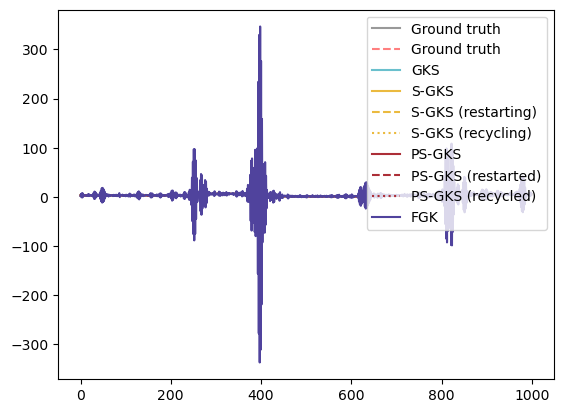

In [16]:
plt.plot(ground_truth, label="Ground truth", color="C9", alpha=0.5)
plt.plot(A.T @ b, label="Ground truth", color="red", alpha=0.5, ls="--")
plt.plot(vdata["x"], label="GKS", color="C0")
plt.plot(data["x"], label="S-GKS", color="C1")
plt.plot(resdata["x"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(resdata["x"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["x"], label="PS-GKS", color="C2")
plt.plot(respdata["x"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["x"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.plot(mmfkdata["x"], label="FGK", color="C7")
plt.legend()
plt.show()

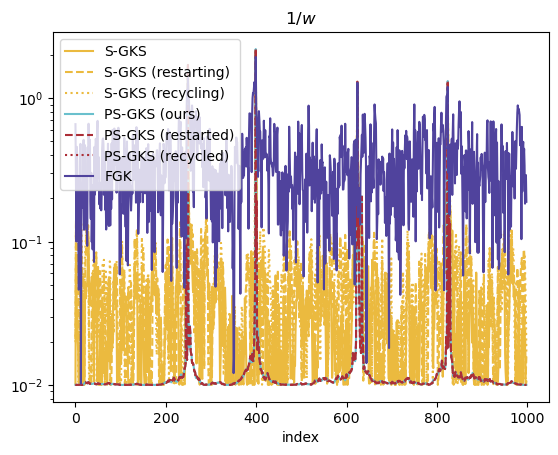

In [17]:
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
plt.semilogy(1.0/data['w'], label="S-GKS", color="C1")
plt.semilogy(1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(1.0/pdata['w'], label="PS-GKS (ours)")
plt.plot(1.0/respdata["w"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(1.0/recpdata["w"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.semilogy(1.0/mmfkdata["w"], label="FGK", color="C7")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

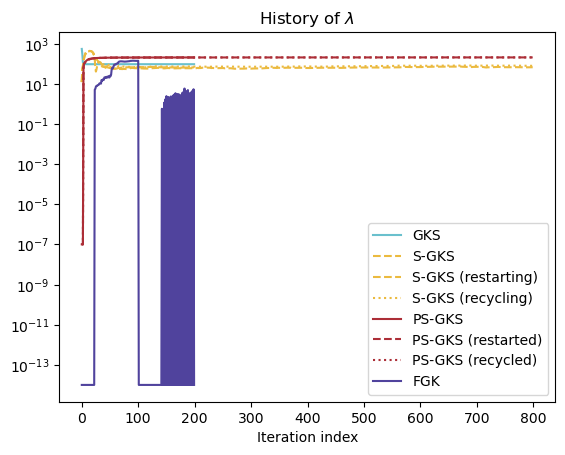

In [18]:
plt.semilogy(vdata["lambda_history"], label="GKS", color="C0")
plt.semilogy(data["lambda_history"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C2")
plt.plot(respdata["lambda_history"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["lambda_history"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.semilogy(mmfkdata["lambda_history"], label="FGK", alpha=1.0, color="C7")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

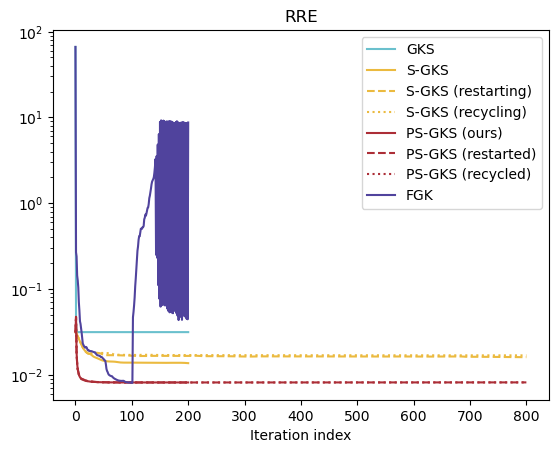

In [19]:
plt.semilogy(vdata["rre_history"], label="GKS", color="C0")
plt.semilogy(data["rre_history"], label="S-GKS", color="C1")
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["rre_history"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["rre_history"], label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmfkdata["rre_history"], label="FGK", alpha=1.0, color="C7")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

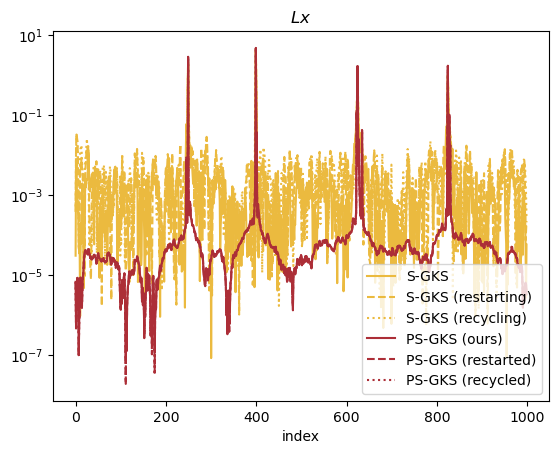

In [20]:
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
plt.semilogy(np.abs(L @ data['x']), label="S-GKS", color="C1")
plt.semilogy(np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(np.abs(L @ pdata['x']), label="PS-GKS (ours)", color="C2")
plt.plot(np.abs(L @ respdata["x"]), label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(np.abs(L @ recpdata["x"]), label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(L @ mmfkdata["x"], label="FGK", color="C7")
plt.title("$L x$")
plt.xlabel("index")
plt.legend()
plt.show()

In [21]:
tmp = np.abs(L @ pdata['x'])
tmp[tmp > 0.1]

array([2.90958525, 4.84862628, 0.11049749, 1.66822907, 0.11403695,
       1.73522648, 0.10406187])

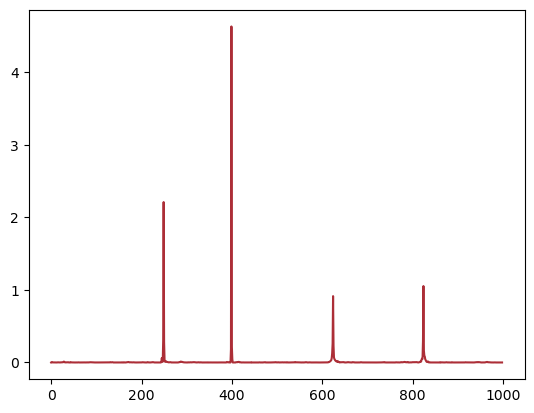

In [22]:
plt.plot(np.abs(L @ data['x']), label="PS-GKS (ours)", color="C2")

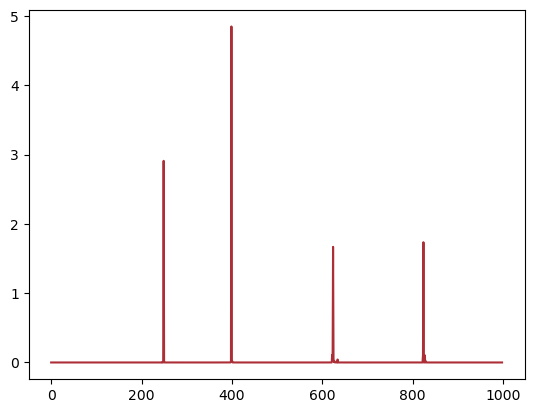

In [23]:
plt.plot(np.abs(L @ pdata['x']), label="PS-GKS (ours)", color="C2") 

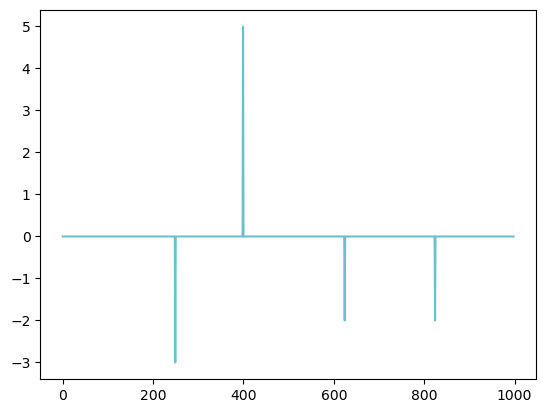

In [24]:
plt.plot(L @ ground_truth)
plt.show()

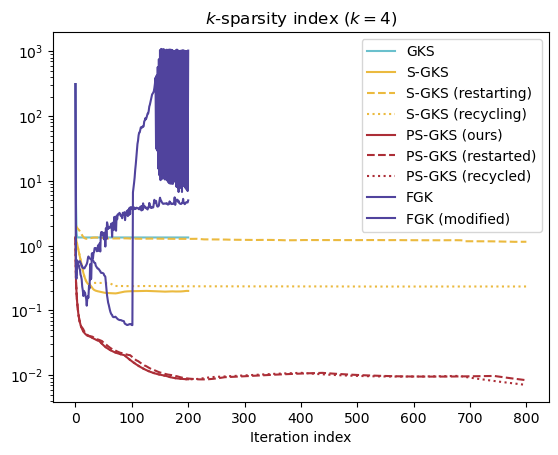

In [25]:
plt.semilogy(vdata["ksparsity_indices"], label="GKS", color="C0")
plt.semilogy(data["ksparsity_indices"], label="S-GKS", color="C1")
plt.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["ksparsity_indices"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["ksparsity_indices"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["ksparsity_indices"], label="PS-GKS (recycled)", color="C2", ls=":")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmfkdata["ksparsity_indices"], label="FGK", alpha=1.0, color="C7")
plt.semilogy(rmmfkdata["ksparsity_indices"], label="FGK (modified)", alpha=1.0, color="C7")
plt.title("$k$-sparsity index ($k = 4$)")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

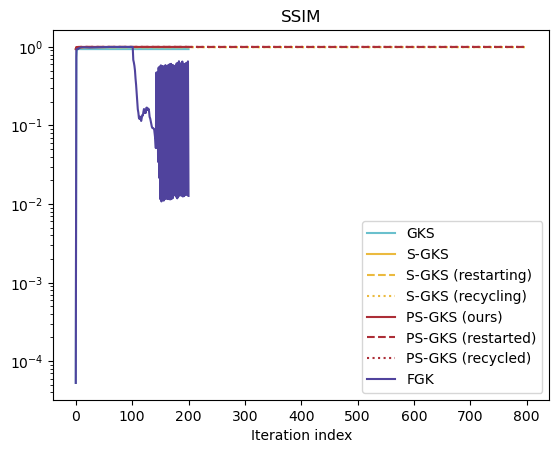

In [26]:
plt.plot(vdata["ssim_history"], label="GKS", color="C0")
plt.plot(data["ssim_history"], label="S-GKS", color="C1")
plt.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C2")
plt.plot(respdata["ssim_history"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["ssim_history"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.semilogy(mmfkdata["ssim_history"], label="FGK", alpha=1.0, color="C7")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

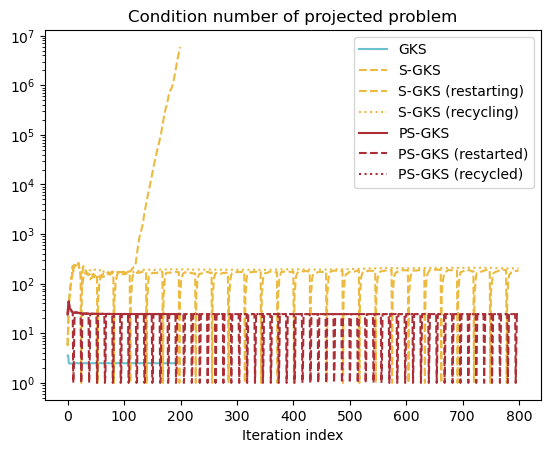

In [27]:
plt.semilogy(vdata["cond_ests"], label="GKS", color="C0")
plt.semilogy(data["cond_ests"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C2")
plt.plot(respdata["cond_ests"], label="PS-GKS (restarted)", color="C2", ls="--")
plt.plot(recpdata["cond_ests"], label="PS-GKS (recycled)", color="C2", ls=":")
plt.title("Condition number of projected problem")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Plots in the paper

In [28]:
# # Create a figure with a 2x3 grid
# fig = plt.figure(figsize=(12, 8))
# gs = gridspec.GridSpec(3, 3, figure=fig)

# # Combine the first two subplots at positions (0,0) and (0,1)
# ax1 = fig.add_subplot(gs[0, :])
# ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
# ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
# ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
# ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
# #ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
# #ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
# ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS (ours)", color="C4")

# inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
# inset_ax.set_xticks([])
# inset_ax.set_yticks([])
# inset_low_coord = 610
# inset_high_coord = 640
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS (ours)", color="C4", marker="o", facecolors="none")

# ax1.indicate_inset_zoom(inset_ax)
# ax1.legend(loc="lower right")
# ax1.set_xlabel("Index")
# ax1.set_title('Reconstructions')



# ax2 = fig.add_subplot(gs[1, :2])
# #plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (ours)", color="C4", s=8, marker="o", facecolors="none")
# ax2.set_title("$1/w$")
# ax2.set_xlabel("Index")
# ax2.set_yscale("log")
# ax2.legend()

# ax4 = fig.add_subplot(gs[1, 2])
# ax4.set_title('Subplot (1,1)')
# ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
# ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
# ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
# ax4.set_title("History of $\\lambda$")
# ax4.set_xlabel("Iteration index")
# ax4.legend()



# # ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C1", marker="x", s=5)

# ax3 = fig.add_subplot(gs[2, 0])
# ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
# ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
# ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax3.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C4")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax3.set_title("RRE")
# ax3.set_xlabel("Iteration index")
# ax3.legend()



# ax6 = fig.add_subplot(gs[2, 1])
# ax6.plot(vdata["ssim_history"], label="GKS", color="C3")
# ax6.plot(data["ssim_history"], label="S-GKS", color="C5")
# ax6.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax6.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax6.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C4")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax6.set_title("SSIM")
# ax6.set_xlabel("Iteration index")
# ax6.legend()


# ax5 = fig.add_subplot(gs[2, 2])
# ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
# ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
# ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
# ax5.set_title("Condition number of projected problem")
# ax5.set_xlabel("Iteration index")
# ax5.legend(loc="lower right")


# # Adjust layout
# fig.tight_layout()
# #fig.savefig("1d_cosine_example_mm.png", dpi=250, bbox_inches=None)
# #fig.savefig("1d_cosine_example_mm.eps", format="eps", dpi=250, bbox_inches=None)
# plt.show()


In [29]:
# # Create a figure with a 2x3 grid
# fig = plt.figure(figsize=(12, 14))
# gs = gridspec.GridSpec(5, 3, figure=fig)

# # Combine the first two subplots at positions (0,0) and (0,1)
# ax1 = fig.add_subplot(gs[0, :])
# ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
# ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
# ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
# ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
# #ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
# #ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
# ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS", color="C4")
# #ax1.plot([i for i in range(len(data["x"]))], respdata["x"], label="PS-GKS (restarting)", color="C4")
# #ax1.plot([i for i in range(len(data["x"]))], recpdata["x"], label="PS-GKS (recycling)", color="C4")
# ax1.plot([i for i in range(len(data["x"]))], mmfkdata["x"], label="FGK", color="C6")

# inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
# inset_ax.set_xticks([])
# inset_ax.set_yticks([])
# inset_low_coord = 610
# inset_high_coord = 640
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
# #inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS", color="C4", marker="o", facecolors="none")
# inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], mmfkdata["x"][inset_low_coord:inset_high_coord], label="FGK", color="C6", marker="<", facecolors="none")

# ax1.indicate_inset_zoom(inset_ax)
# ax1.legend(loc="lower right")
# ax1.set_xlabel("Index")
# ax1.set_title('Reconstructions')



# ax2 = fig.add_subplot(gs[1, :])
# #plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
# #ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
# ax2.scatter([i for i in range(len(data["w"]))], 1.0/mmfkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
# ax2.set_title("$1/w$")
# ax2.set_xlabel("Index")
# ax2.set_yscale("log")
# ax2.legend()


# # ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C1", marker="x", s=5)

# ax3 = fig.add_subplot(gs[2, :])
# ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
# ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
# ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
# ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
# ax3.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
# ax3.semilogy(resdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="--")
# ax3.semilogy(recdata["rre_history"], label="PS-GKS (recycling)", color="C4", ls=":")
# ax3.semilogy(mmfkdata["rre_history"], label="FGK", color="C6")
# ax3.semilogy(rmmfkdata["rre_history"], label="FGK (modified)", color="C6", ls="--")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# #ax3.set_xscale("log")
# ax3.set_title("RRE")
# ax3.set_xlabel("Iteration index")
# ax3.legend(loc="upper right")




# ax4 = fig.add_subplot(gs[4, :2])
# ax4.set_title('Subplot (1,1)')
# ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
# ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
# ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
# ax4.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="--")
# ax4.semilogy(recpdata["lambda_history"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=":")
# ax4.semilogy(mmfkdata["lambda_history"], label="FGK", alpha=1.0, color="C6")
# ax4.semilogy(rmmfkdata["lambda_history"], label="FGK (modified)", alpha=1.0, color="C6")
# ax4.set_title("History of $\\lambda$")
# ax4.set_xlabel("Iteration index")
# ax4.legend()





# ax6 = fig.add_subplot(gs[3, :])
# ax6.semilogy(vdata["ksparsity_indices"], label="GKS", color="C3")
# ax6.semilogy(data["ksparsity_indices"], label="S-GKS", color="C5")
# ax6.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C5", ls="--")
# ax6.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C5", ls=":")
# ax6.semilogy(pdata["ksparsity_indices"], label="PS-GKS", color="C4")
# ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (restarting)", color="C4", ls="--")
# ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (recycling)", color="C4", ls=":")
# ax6.semilogy(mmfkdata["ksparsity_indices"], label="FGK", color="C6")
# ax6.semilogy(rmmfkdata["ksparsity_indices"], label="FGK (modified)", color="C6", ls="--")
# #plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
# ax6.set_title("$s$-sparsity $\sigma_s$, $s = 15$")
# ax6.set_xlabel("Iteration index")
# ax6.legend()


# ax5 = fig.add_subplot(gs[4, 2])
# ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
# ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
# ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
# ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
# ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
# ax5.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="--")
# ax5.semilogy(recpdata["cond_ests"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=":")
# ax5.semilogy(mmfkdata["cond_ests"], label="FGK", alpha=1.0, color="C6")
# ax5.semilogy(rmmfkdata["cond_ests"], label="FGK (modified)", alpha=1.0, color="C6", ls="--")
# ax5.set_title("Condition number of projected problem")
# ax5.set_xlabel("Iteration index")
# ax5.legend(loc="lower right")


# # Adjust layout
# fig.tight_layout()
# fig.savefig("1d_cosine_example_mm.png", dpi=250, bbox_inches=None)
# fig.savefig("1d_cosine_example_mm.eps", format="eps", dpi=250, bbox_inches=None)
# plt.show()


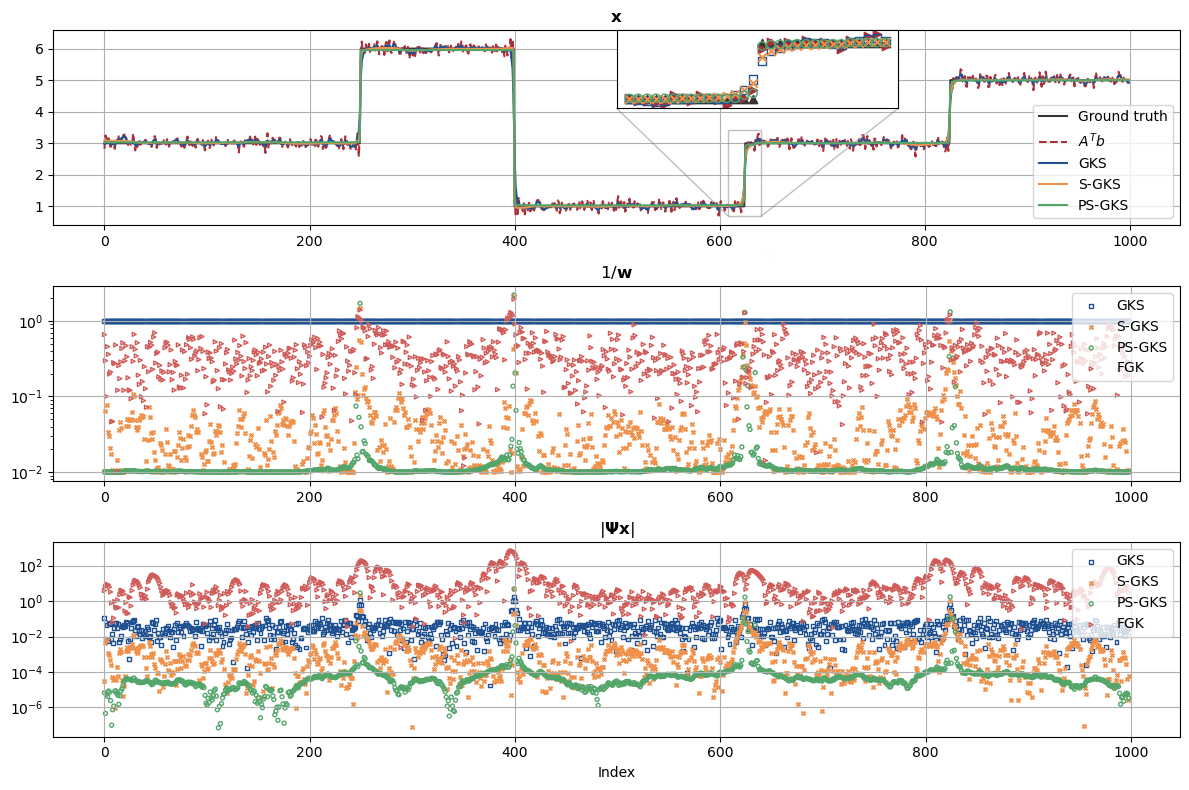

In [34]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(3, 1, figure=fig)

# Combine the first two subplots at positions (0,0) and (0,1)
ax1 = fig.add_subplot(gs[0])
ax1.plot([i for i in range(len(data["x"]))], ground_truth, label="Ground truth", color="C9", alpha=1.0)
ax1.plot([i for i in range(len(data["x"]))], A.T @ b, label="$A^T b$", color="C2", alpha=1.0, ls="--")
ax1.plot([i for i in range(len(data["x"]))], vdata["x"], label="GKS", color="C3")
ax1.plot([i for i in range(len(data["x"]))], data["x"], label="S-GKS", color="C5")
#ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C3", ls="--")
#ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C3", ls=":")
ax1.plot([i for i in range(len(data["x"]))], pdata["x"], label="PS-GKS", color="C4")
#ax1.plot([i for i in range(len(data["x"]))], respdata["x"], label="PS-GKS (restarting)", color="C4")
#ax1.plot([i for i in range(len(data["x"]))], recpdata["x"], label="PS-GKS (recycling)", color="C4")
#ax1.plot([i for i in range(len(data["x"]))], mmfkdata["x"], label="FGK", color="C6")

inset_ax = ax1.inset_axes([0.5, 0.6, 0.25, 0.4])  # [left, bottom, width, height]
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_low_coord = 610
inset_high_coord = 640
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], ground_truth[inset_low_coord:inset_high_coord], label="Ground truth", color="C9", alpha=1.0, marker="^")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], (A.T @ b)[inset_low_coord:inset_high_coord], label="$A^T b$", color="C2", alpha=1.0, marker=">")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], vdata["x"][inset_low_coord:inset_high_coord], label="GKS", color="C3", marker="s", facecolors="none")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], data["x"][inset_low_coord:inset_high_coord], label="S-GKS", color="C5", marker="x")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], resdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (restarting)", color="C3", ls="--")
#inset_ax.plot([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], recdata["x"][inset_low_coord:inset_high_coord], label="S-GKS (recycling)", color="C3", ls=":")
inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], pdata["x"][inset_low_coord:inset_high_coord], label="PS-GKS", color="C4", marker="o", facecolors="none")
#inset_ax.scatter([i for i in range(len(data["x"]))][inset_low_coord:inset_high_coord], mmfkdata["x"][inset_low_coord:inset_high_coord], label="FGK", color="C6", marker="<", facecolors="none")
inset_ax.grid()

ax1.indicate_inset_zoom(inset_ax)
ax1.legend(loc="lower right")
#ax1.set_xlabel("Index")
ax1.set_title('$\\mathbf{x}$')
ax1.grid()


ax2 = fig.add_subplot(gs[1])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/vdata['w'], label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C5", marker="x", s=8)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
#ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/mmfkdata['w'], label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax2.set_title("$1/\\mathbf{w}$")
#ax2.set_xlabel("Index")
ax2.set_yscale("log")
ax2.legend(loc="upper right")
ax2.grid()





ax10 = fig.add_subplot(gs[2])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ vdata['x']), label="GKS", color="C3", marker="s", s=8, facecolors="none")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ data['x']), label="S-GKS", color="C5", marker="x", s=8)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ resdata['x']), label="S-GKS (restarting)", color="C1", ls="--", marker="x", s=5)
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ recdata['x']), label="S-GKS (recycling)", color="C1", ls=":")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS", color="C4", s=8, marker="o", facecolors="none")
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS (restarting)", color="C4", s=8, marker=">", facecolors="none")
#ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ pdata['x']), label="PS-GKS (recycling)", color="C4", s=8, marker="^", facecolors="none")
ax10.scatter([i for i in range(len(data["w"]))], np.abs(L @ mmfkdata['x']), label="FGK", color="C6", s=8, marker=">", facecolors="none")
ax10.set_title("$| \\boldsymbol{\\Psi} \\mathbf{x} |$")
ax10.set_xlabel("Index")
ax10.set_yscale("log")
ax10.legend(loc="upper right")
ax10.grid()


# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_mm_reconstructions.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_mm_reconstructions.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


In [37]:
np.linalg.norm( (mmfkdata['Z'].T @ mmfkdata['Z']) - np.eye(mmfkdata['Z'].shape[1]) )

16884321730.757149

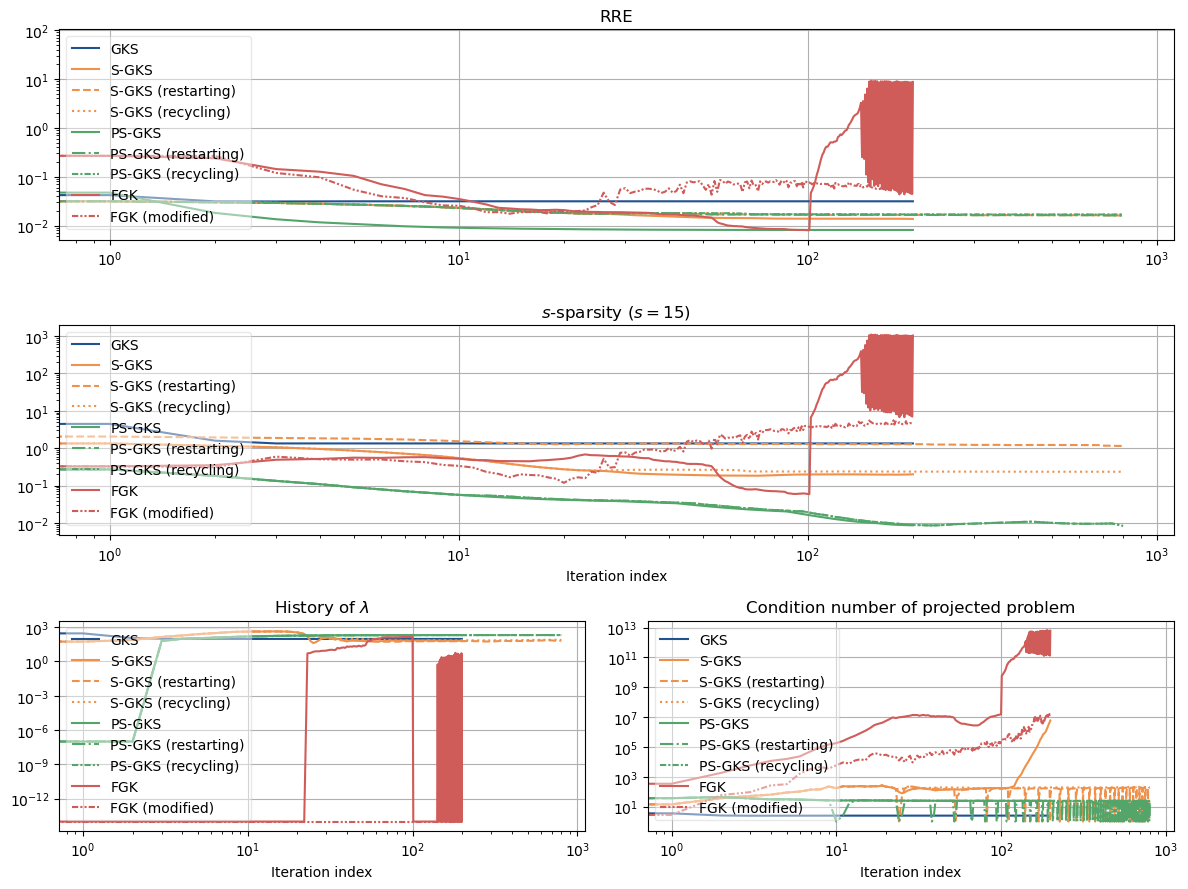

In [31]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(12, 9))
gs = gridspec.GridSpec(3, 2, figure=fig)


ax3 = fig.add_subplot(gs[0,:])
ax3.semilogy(vdata["rre_history"], label="GKS", color="C3")
ax3.semilogy(data["rre_history"], label="S-GKS", color="C5")
ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax3.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
ax3.semilogy(resdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="dashdot")
ax3.semilogy(recdata["rre_history"], label="PS-GKS (recycling)", color="C4", ls=(0, (3, 1, 1, 1)))
ax3.semilogy(mmfkdata["rre_history"], label="FGK", color="C6")
ax3.semilogy(rmmfkdata["rre_history"], label="FGK (modified)", color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
#ax3.set_xscale("log")
ax3.set_title("RRE")
#ax3.set_xlabel("Iteration index")
ax3.set_xscale("log")
ax3.legend(loc="upper right")
ax3.legend().get_frame().set_alpha(0.45)
ax3.grid()



ax4 = fig.add_subplot(gs[2,0])
ax4.set_title('Subplot (1,1)')
ax4.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C5")
ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C4")
ax4.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="dashdot")
ax4.semilogy(recpdata["lambda_history"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=(0, (3, 1, 1, 1)))
ax4.semilogy(mmfkdata["lambda_history"], label="FGK", alpha=1.0, color="C6")
ax4.semilogy(rmmfkdata["lambda_history"], label="FGK (modified)", alpha=1.0, color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
ax4.set_title("History of $\\lambda$")
ax4.set_xlabel("Iteration index")
ax4.legend(loc="upper left").get_frame().set_alpha(0.45)
ax4.set_xscale("log")
ax4.grid()
#ax4.legend().get_frame().set_alpha(0.45)



ax6 = fig.add_subplot(gs[1,:])
ax6.semilogy(vdata["ksparsity_indices"], label="GKS", color="C3")
ax6.semilogy(data["ksparsity_indices"], label="S-GKS", color="C5")
ax6.semilogy(resdata["ksparsity_indices"], label="S-GKS (restarting)", color="C5", ls="--")
ax6.semilogy(recdata["ksparsity_indices"], label="S-GKS (recycling)", color="C5", ls=":")
ax6.semilogy(pdata["ksparsity_indices"], label="PS-GKS", color="C4")
ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (restarting)", color="C4", ls="dashdot")
ax6.semilogy(respdata["ksparsity_indices"], label="PS-GKS (recycling)", color="C4", ls=(0, (3, 1, 1, 1)))
ax6.semilogy(mmfkdata["ksparsity_indices"], label="FGK", color="C6")
ax6.semilogy(rmmfkdata["ksparsity_indices"], label="FGK (modified)", color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
ax6.set_title("$s$-sparsity ($s = 15$)")
ax6.set_xlabel("Iteration index")
#ax6.set_xlim(None, 10**3)
ax6.set_xscale("log")
ax6.legend(loc="upper right")
ax6.legend(loc="upper left").get_frame().set_alpha(0.45)
ax6.grid()


ax5 = fig.add_subplot(gs[2, 1])
ax5.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax5.semilogy(data["cond_ests"], label="S-GKS", alpha=1.0, color="C5")
ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C5")
ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C5")
ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C4")
ax5.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", alpha=1.0, color="C4", ls="dashdot")
ax5.semilogy(recpdata["cond_ests"], label="PS-GKS (recycling)", alpha=1.0, color="C4", ls=(0, (3, 1, 1, 1)))
ax5.semilogy(mmfkdata["cond_ests"], label="FGK", alpha=1.0, color="C6")
ax5.semilogy(rmmfkdata["cond_ests"], label="FGK (modified)", alpha=1.0, color="C6", ls=(0, (3, 1, 1, 1, 1, 1)))
ax5.set_title("Condition number of projected problem")
ax5.set_xlabel("Iteration index")
ax5.set_xscale("log")
ax5.legend(loc="upper left").get_frame().set_alpha(0.45)
ax5.grid()


# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example_mm_performance.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_mm_performance.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


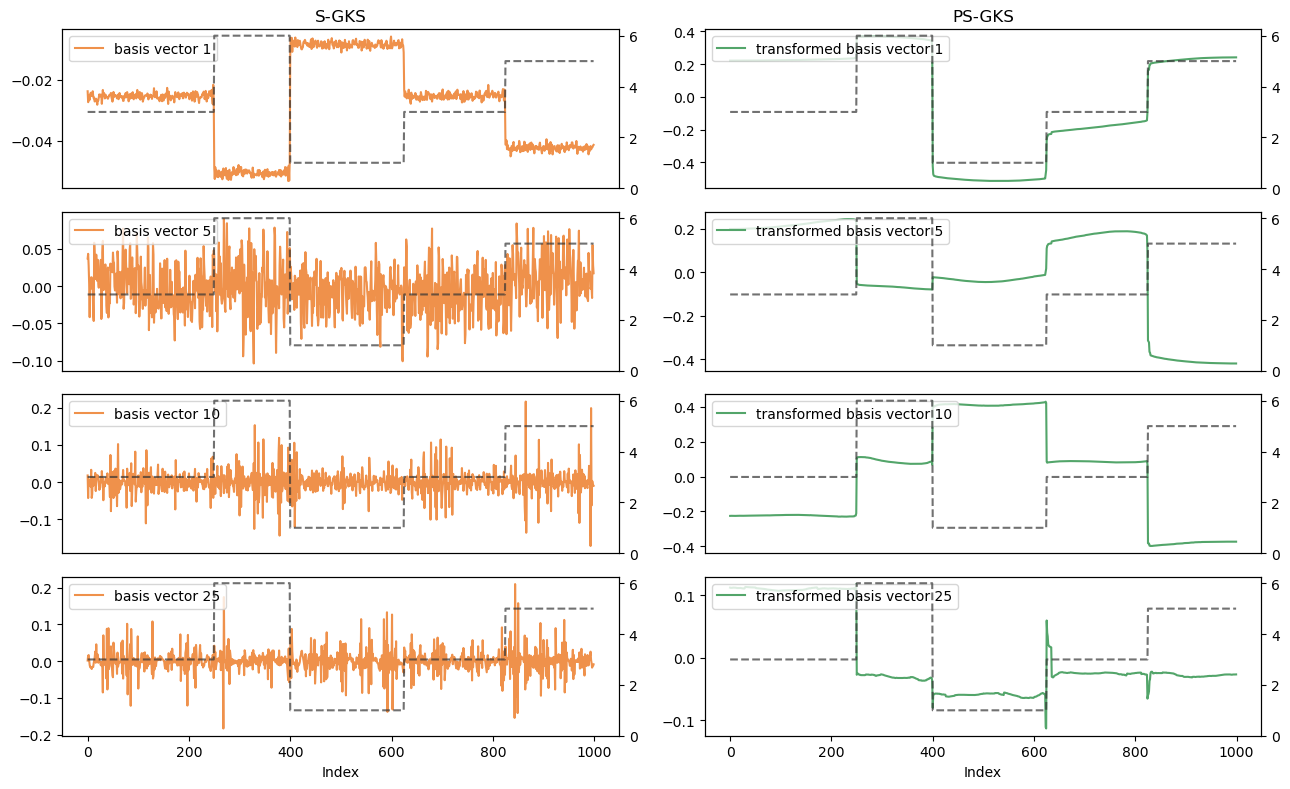

In [32]:
fig, axs = plt.subplots(4,2, figsize=(13,8))

loc = "upper left"

kk = 0
axs[0,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[0,0].legend(loc=loc)
axs[0,0].set_xticks([])
axs[0,0].set_title("S-GKS")
axst = axs[0,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[1,0].legend(loc=loc)
axs[1,0].set_xticks([])
axst = axs[1,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[2,0].legend(loc=loc)
axs[2,0].set_xticks([])
axst = axs[2,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
axs[3,0].legend(loc=loc)
axs[3,0].set_xlabel("Index")
axst = axs[3,0].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])




kk = 0
axs[0,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[0,1].legend(loc=loc)
axs[0,1].set_xticks([])
axs[0,1].set_title("PS-GKS")
axst = axs[0,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 4
axs[1,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[1,1].legend(loc=loc)
axs[1,1].set_xticks([])
axst = axs[1,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 9
axs[2,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[2,1].legend(loc=loc)
axs[2,1].set_xticks([])
axst = axs[2,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

kk = 24
axs[3,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
axs[3,1].legend(loc=loc)
axs[3,1].set_xlabel("Index")
axst = axs[3,1].twinx()
axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
axst.set_yticks([0, 2, 4, 6])

fig.tight_layout()
fig.savefig("1d_cosine_example_basis_vectors_mm.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

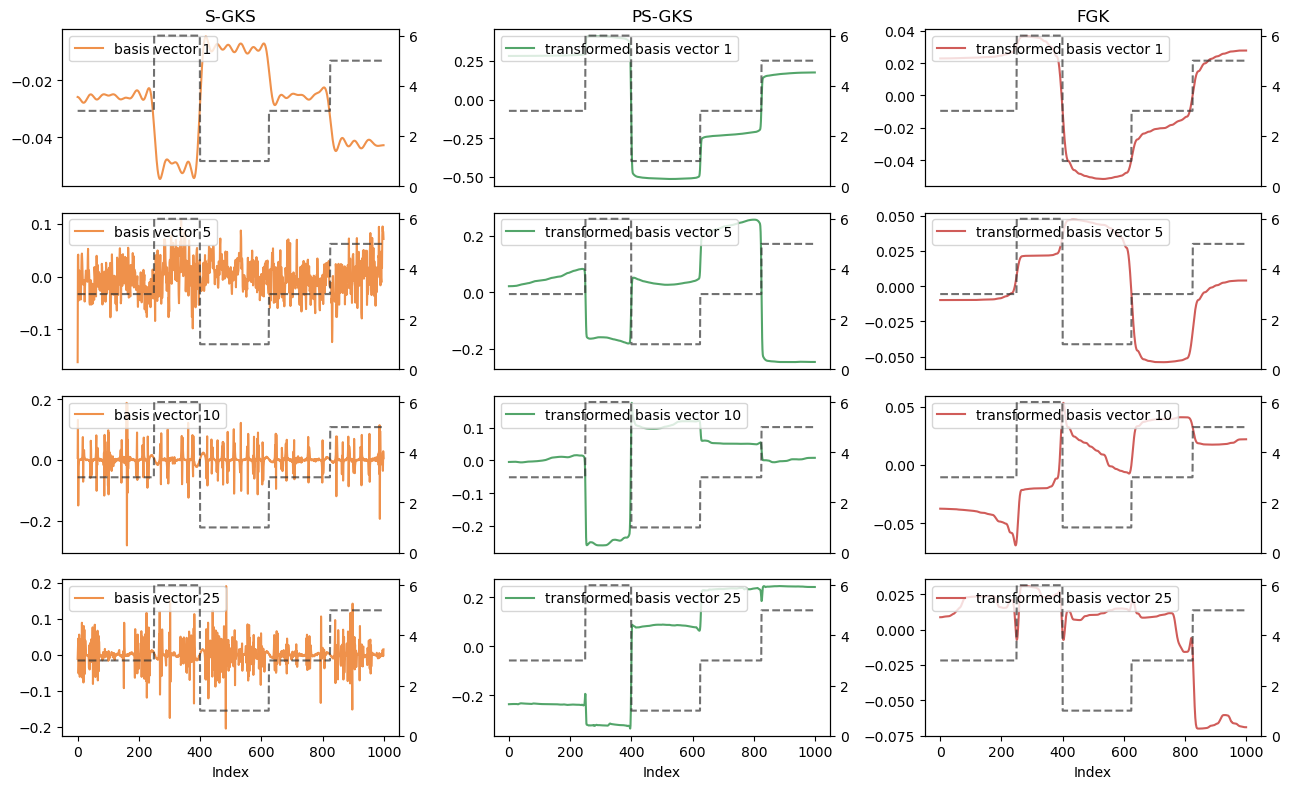

In [30]:
# fig, axs = plt.subplots(4,3, figsize=(13,8))

# loc = "upper left"

# kk = 0
# axs[0,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[0,0].legend(loc=loc)
# axs[0,0].set_xticks([])
# axs[0,0].set_title("S-GKS")
# axst = axs[0,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 4
# axs[1,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[1,0].legend(loc=loc)
# axs[1,0].set_xticks([])
# axst = axs[1,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 9
# axs[2,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[2,0].legend(loc=loc)
# axs[2,0].set_xticks([])
# axst = axs[2,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 24
# axs[3,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C5")
# axs[3,0].legend(loc=loc)
# axs[3,0].set_xlabel("Index")
# axst = axs[3,0].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])




# kk = 0
# axs[0,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[0,1].legend(loc=loc)
# axs[0,1].set_xticks([])
# axs[0,1].set_title("PS-GKS")
# axst = axs[0,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 4
# axs[1,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[1,1].legend(loc=loc)
# axs[1,1].set_xticks([])
# axst = axs[1,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 9
# axs[2,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[2,1].legend(loc=loc)
# axs[2,1].set_xticks([])
# axst = axs[2,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 24
# axs[3,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C4")
# axs[3,1].legend(loc=loc)
# axs[3,1].set_xlabel("Index")
# axst = axs[3,1].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])





# kk = 0
# axs[0,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[0,2].legend(loc=loc)
# axs[0,2].set_xticks([])
# axs[0,2].set_title("FGK")
# axst = axs[0,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 4
# axs[1,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[1,2].legend(loc=loc)
# axs[1,2].set_xticks([])
# axst = axs[1,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 9
# axs[2,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[2,2].legend(loc=loc)
# axs[2,2].set_xticks([])
# axst = axs[2,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])

# kk = 24
# axs[3,2].plot(mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]), label=f"transformed basis vector {kk+1}", color="C6")
# axs[3,2].legend(loc=loc)
# axs[3,2].set_xlabel("Index")
# axst = axs[3,2].twinx()
# axst.plot(ground_truth, color="C9", alpha=0.7, ls="--")
# axst.set_yticks([0, 2, 4, 6])




# fig.tight_layout()
# #fig.savefig("1d_cosine_example_basis_vectors_mm.png", dpi=250, bbox_inches=None)
# #fig.savefig("1d_cosine_example_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)

# plt.show()

In [27]:
mmfkdata.keys()

dict_keys(['x', 'V', 'U', 'H', 'Z', 'w', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history'])